# Probability Distribution of Sentinel Data

## Download images

**Kraków** and **Olkusz** (urban areas), on the same 512 × 512 grid with 10 m pixel spacing.
Sentinel-2: **B02, B03, B04** (original DN). Sentinel-1 GRD: **VV, VH** (amplitude).
GeoTIFFs in `images/` retain the data; PNGs are display previews.

Source: [Microsoft Planetary Computer](https://planetarycomputer.microsoft.com/catalog).
Contains modified Copernicus Sentinel data (2024).

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as mp
import planetary_computer
import rasterio
import skopt as opt
from PIL import Image
from pystac_client import Client
from rasterio.transform import from_origin
from rasterio.warp import transform, reproject
from scipy import optimize, fftpack

LAB_DIR = Path("lab_2") if Path("lab_2/probability_distribution.ipynb").exists() else Path(".")
IMAGE_DIR = LAB_DIR / "images"
IMAGE_DIR.mkdir(exist_ok=True)

In [2]:
sites = {
    "cracow": ("Kraków", 19.94, 50.06),
    "olkusz": ("Olkusz", 19.56, 50.28),
}
sensors = {
    "sentinel2": ("sentinel-2-l2a", ["B02", "B03", "B04"]),
    "sentinel1": ("sentinel-1-grd", ["vv", "vh"]),
}
catalog = None
for name, (label, lon, lat) in sites.items():
    x, y = transform("EPSG:4326", "EPSG:32634", [lon], [lat])
    grid = from_origin(round(x[0] / 10) * 10 - 2560, round(y[0] / 10) * 10 + 2560, 10, 10)
    for sensor, (collection, bands) in sensors.items():
        path = IMAGE_DIR / f"{name}_{sensor}.tif"
        if path.exists():
            continue
        if catalog is None:
            catalog = Client.open(
                "https://planetarycomputer.microsoft.com/api/stac/v1",
                modifier=planetary_computer.sign_inplace,
            )
        query = {"eo:cloud_cover": {"lt": 10}} if sensor == "sentinel2" else {
            "sar:instrument_mode": {"eq": "IW"}, "sat:orbit_state": {"eq": "ascending"},
        }
        sort = "properties.eo:cloud_cover" if sensor == "sentinel2" else "properties.datetime"
        search = catalog.search(
            collections=[collection],
            bbox=[lon - 0.05, lat - 0.03, lon + 0.05, lat + 0.03],
            datetime="2024-08-01/2024-08-31", query=query,
            sortby=[{"field": sort, "direction": "asc"}], max_items=12,
        )
        for item in search.items():
            arrays = []
            with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_TIMEOUT=60):
                for band in bands:
                    with rasterio.open(item.assets[band].href) as src:
                        pixels = np.zeros((512, 512), dtype=src.dtypes[0])
                        gcps, gcp_crs = src.gcps
                        georef = {"src_transform": src.transform, "src_crs": src.crs} if src.crs else {
                            "gcps": gcps, "src_crs": gcp_crs,
                        }
                        reproject(rasterio.band(src, 1), pixels, dst_transform=grid,
                                  dst_crs="EPSG:32634", dst_nodata=0, **georef)
                        if (pixels == 0).any():
                            break
                        arrays.append(pixels)
            if len(arrays) == len(bands):
                break
        else:
            raise ValueError(f"No complete crop: {label}, {sensor}")
        data = np.stack(arrays)
        with rasterio.open(
            path, "w", driver="GTiff", width=512, height=512, count=len(bands),
            dtype=data.dtype, crs="EPSG:32634", transform=grid, nodata=0, compress="deflate",
        ) as dst:
            dst.write(data)
            dst.descriptions = tuple(bands)
            dst.update_tags(scene=item.id, date=item.datetime.isoformat())
        print(label, sensor, item.datetime.date(), data.shape, flush=True)

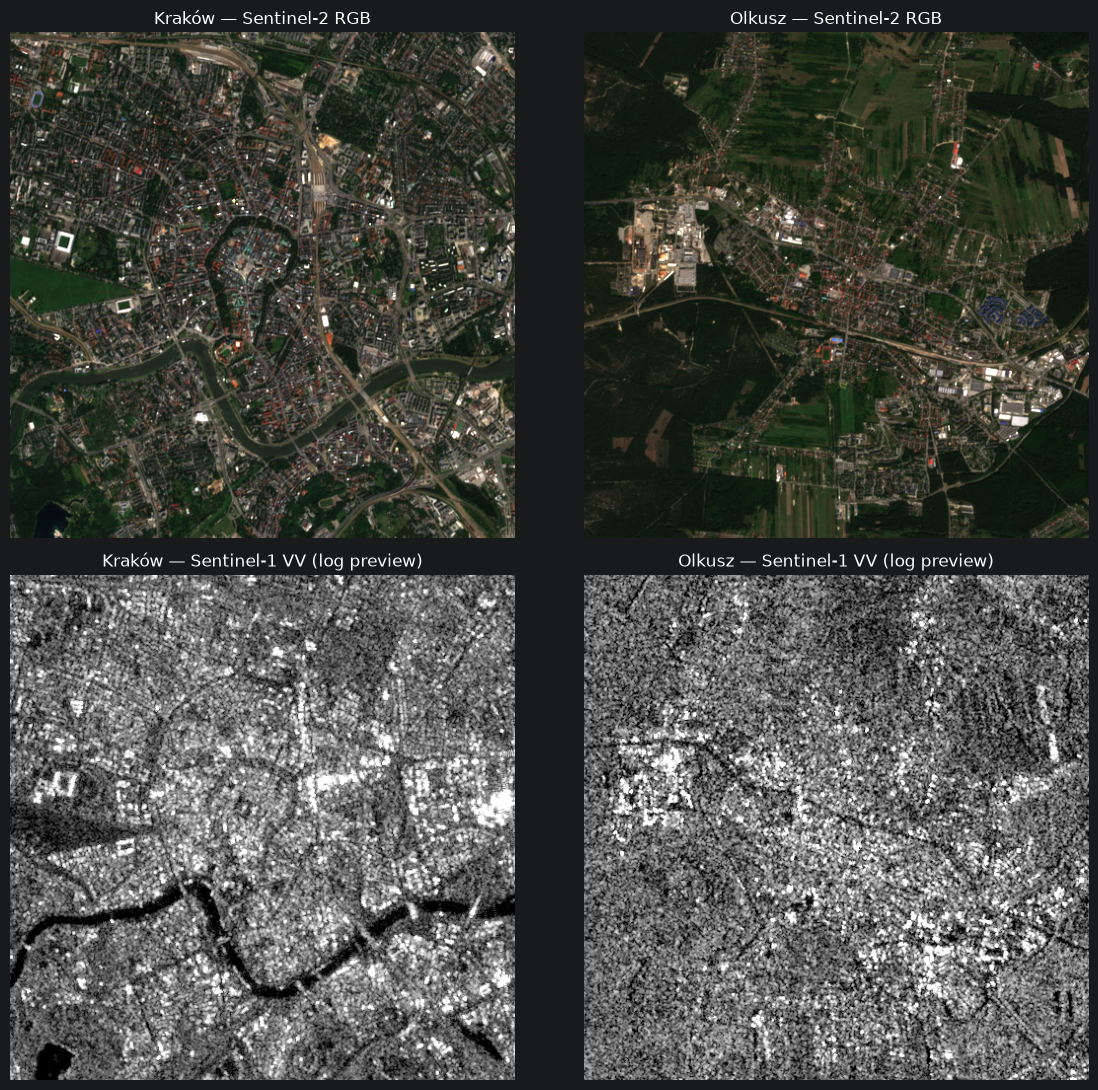

In [3]:
s2_images, s1_images = {}, {}
fig, axes = mp.subplots(2, 2, figsize=(12, 11))
for col, (name, (label, _, _)) in enumerate(sites.items()):
    with rasterio.open(IMAGE_DIR / f"{name}_sentinel2.tif") as src:
        s2_images[name] = src.read()
    with rasterio.open(IMAGE_DIR / f"{name}_sentinel1.tif") as src:
        s1_images[name] = src.read()
    rgb = s2_images[name][[2, 1, 0]].transpose(1, 2, 0).astype(float)
    rgb = np.clip((rgb - 1000) / 3000, 0, 1)
    radar = np.log1p(s1_images[name][0].astype(float))
    low, high = np.percentile(radar, [2, 98])
    radar = np.clip((radar - low) / (high - low), 0, 1)
    Image.fromarray((rgb * 255).astype("uint8")).save(IMAGE_DIR / f"{name}_sentinel2.png")
    Image.fromarray((radar * 255).astype("uint8")).save(IMAGE_DIR / f"{name}_sentinel1.png")
    axes[0, col].imshow(rgb)
    axes[0, col].set_title(label + " — Sentinel-2 RGB")
    axes[1, col].imshow(radar, cmap="gray", vmin=0, vmax=1)
    axes[1, col].set_title(label + " — Sentinel-1 VV (log preview)")
    for ax in axes[:, col]:
        ax.axis("off")
mp.tight_layout()
mp.show()

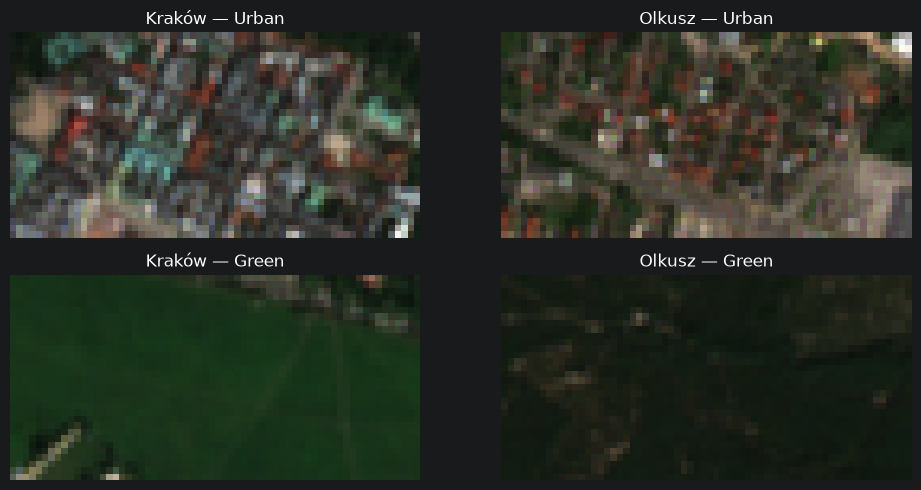

In [4]:
# Row start, row stop, column start, column stop.
regions = {
    "cracow": {"Urban": (200, 232, 220, 284), "Green": (237, 269, 8, 72)},
    "olkusz": {"Urban": (215, 247, 250, 314), "Green": (345, 377, 20, 84)},
}
s2_regions, s1_regions = {}, {}
fig, axes = mp.subplots(2, 2, figsize=(10, 5))
for col, name in enumerate(sites):
    s2_regions[name], s1_regions[name] = {}, {}
    for row, (region, (y0, y1, x0, x1)) in enumerate(regions[name].items()):
        s2_regions[name][region] = s2_images[name][:, y0:y1, x0:x1]
        s1_regions[name][region] = s1_images[name][:, y0:y1, x0:x1]
        rgb = s2_regions[name][region][[2, 1, 0]].transpose(1, 2, 0).astype(float)
        axes[row, col].imshow(np.clip((rgb - 1000) / 3000, 0, 1))
        axes[row, col].set_title(sites[name][0] + " — " + region)
        axes[row, col].axis("off")
mp.tight_layout()
mp.show()

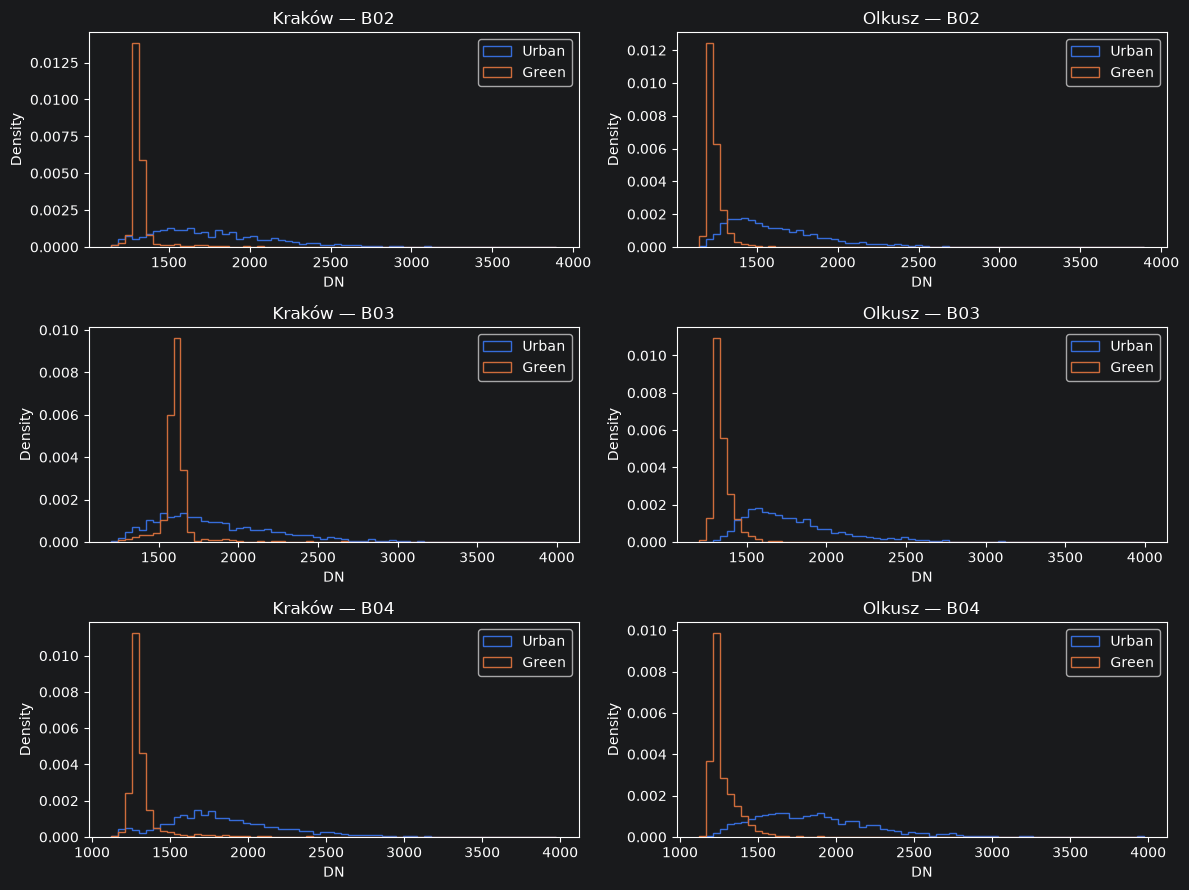

In [5]:
fig, axes = mp.subplots(3, 2, figsize=(12, 9))
for band, title in enumerate(["B02", "B03", "B04"]):
    values = np.concatenate([area[band].ravel()
                             for city in s2_regions.values() for area in city.values()])
    bins = np.linspace(values.min(), values.max() + 1, 65)
    for col, name in enumerate(sites):
        ax = axes[band, col]
        for region, area in s2_regions[name].items():
            values = area[band].ravel()
            ax.hist(values[values > 0], bins=bins, density=True, histtype="step", label=region)
        ax.set_title(sites[name][0] + " — " + title)
        ax.set_xlabel("DN")
        ax.set_ylabel("Density")
        ax.legend()
mp.tight_layout()
mp.show()

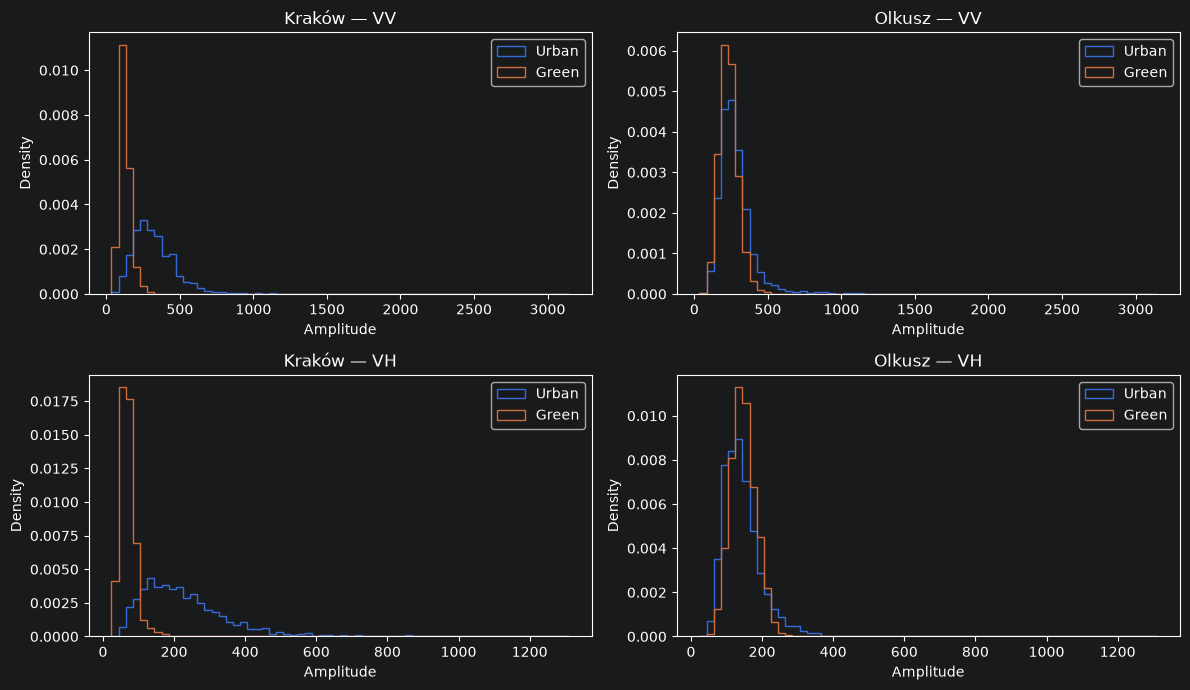

In [6]:
fig, axes = mp.subplots(2, 2, figsize=(12, 7))
for band, title in enumerate(["VV", "VH"]):
    values = np.concatenate([area[band].ravel()
                             for city in s1_regions.values() for area in city.values()])
    bins = np.linspace(values.min(), values.max() + 1, 65)
    for col, name in enumerate(sites):
        ax = axes[band, col]
        for region, area in s1_regions[name].items():
            values = area[band].ravel()
            ax.hist(values[values > 0], bins=bins, density=True, histtype="step", label=region)
        ax.set_title(sites[name][0] + " — " + title)
        ax.set_xlabel("Amplitude")
        ax.set_ylabel("Density")
        ax.legend()
mp.tight_layout()
mp.show()

In [7]:
original = s2_images["cracow"][2].copy()
rng = np.random.default_rng(42)
random_bits = rng.integers(0, 4, original.shape, dtype=np.uint16)
manipulated = (original & np.uint16(0xFFFC)) | random_bits
difference = manipulated.astype(int) - original.astype(int)
print("Maximum change:", np.abs(difference).max(), "DN")
print("Changed pixels:", round(100 * np.mean(difference != 0), 2), "%")

Maximum change: 3 DN
Changed pixels: 74.87 %


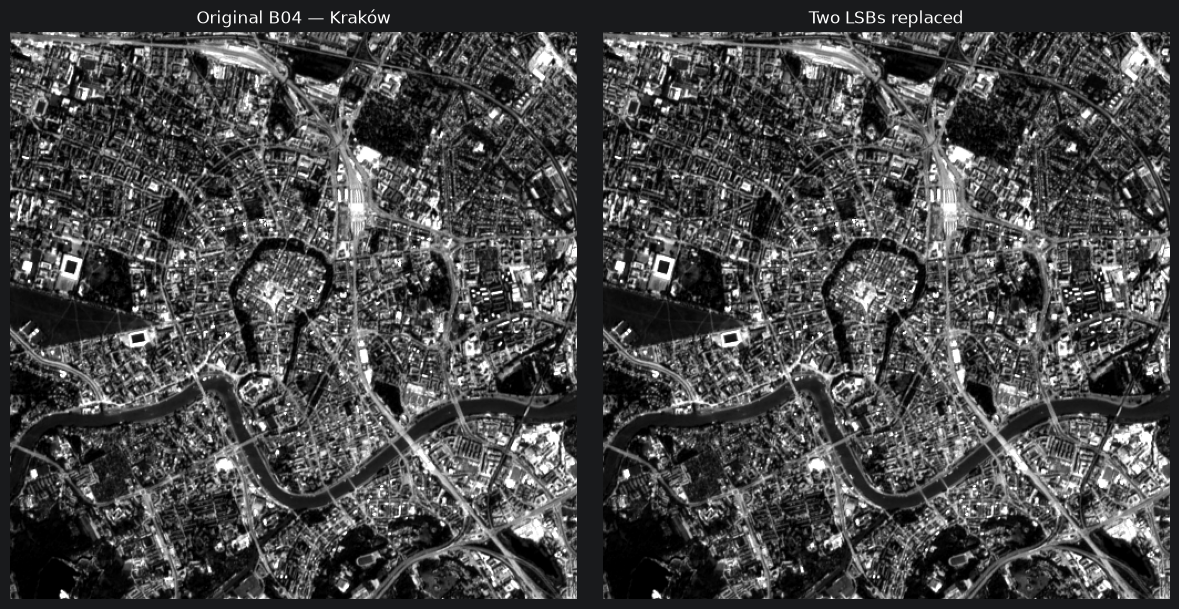

In [8]:
low, high = np.percentile(original, [2, 98])
fig, axes = mp.subplots(1, 2, figsize=(12, 6))
for ax, image, title in zip(axes, [original, manipulated], ["Original B04 — Kraków", "Two LSBs replaced"]):
    ax.imshow(image, cmap="gray", vmin=low, vmax=high)
    ax.set_title(title)
    ax.axis("off")
mp.tight_layout()
mp.show()

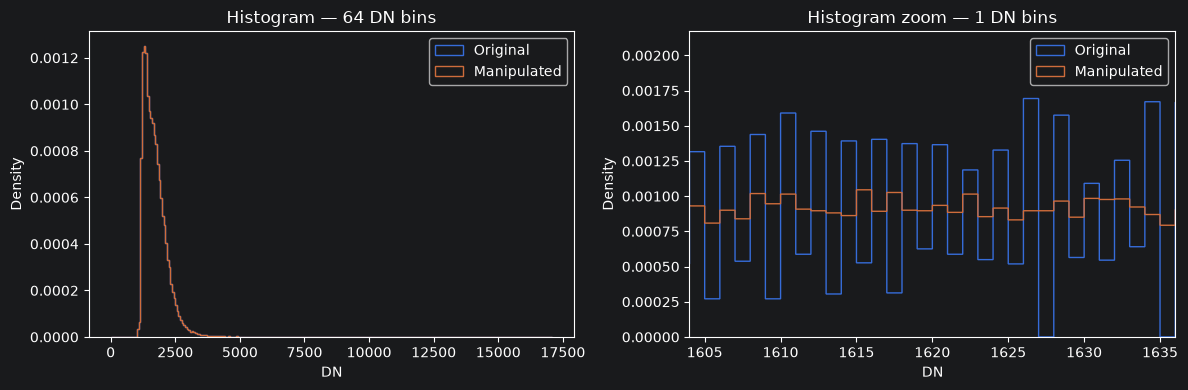

In [9]:
max_dn = int(max(original.max(), manipulated.max())) + 1
fig, axes = mp.subplots(1, 2, figsize=(12, 4))
for image, label in [(original, "Original"), (manipulated, "Manipulated")]:
    axes[0].hist(image.ravel(), bins=np.arange(0, max_dn + 64, 64),
                 density=True, histtype="step", label=label)
    axes[1].hist(image.ravel(), bins=np.arange(max_dn + 1),
                 density=True, histtype="step", label=label)
center = int(np.median(original))
axes[1].set_xlim(center - 16, center + 16)
axes[0].set_title("Histogram — 64 DN bins")
axes[1].set_title("Histogram zoom — 1 DN bins")
for ax in axes:
    ax.set_xlabel("DN")
    ax.set_ylabel("Density")
    ax.legend()
mp.tight_layout()
mp.show()

## Basic Optimization

Examples provided for the optional compressive sensing part.

In [9]:
def f(y):
    return -np.exp(-(y-2)**2)

result = optimize.minimize_scalar(f)
print(result)

 message: 
          Optimization terminated successfully;
          The returned value satisfies the termination criteria
          (using xtol = 1.48e-08 )
 success: True
     fun: -1.0
       x: 1.9999999955459995
     nit: 6
    nfev: 10



### Using minimize function
We can also use Python's minimize or maximize function (with the ''key'' option) to optimize the function!

You can also pass more arguments.

Why to use the "optimize" function then?

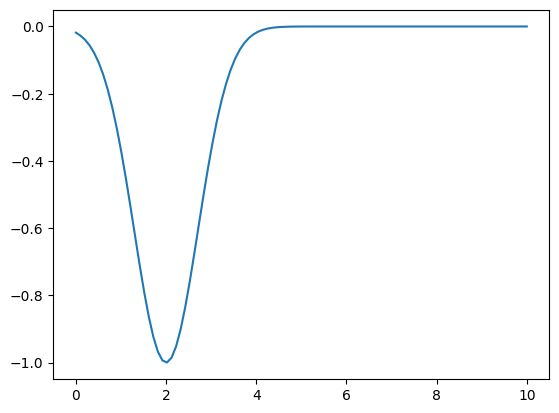

2.0202020202020203


In [3]:
y = np.linspace(0,10,100)
mp.plot(y,-np.exp(-(y-2)**2)); mp.show()
#print(max(y, key=lambda x: np.sinc(x-5)))

print(min(y, key=lambda x: -np.exp(-(x-2)**2)))

### Rosenbrock function

Now we optimize the infamous Rosenbrock function.

$f(x,y) = 0.5*(1-x)^2 + (y - x^2)^2$

In [4]:
def f(x):   # The rosenbrock function
    return .5*(1 - x[0])**2 + (x[1] - x[0]**2)**2
optimize.minimize(f, [0,-1], method="CG")

 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: 1.2743806081839638e-11
       x: [ 1.000e+00  1.000e+00]
     nit: 8
     jac: [-2.100e-07  2.518e-06]
    nfev: 48
    njev: 16

What happens if we change the seed to something very far from the solution point?

In [5]:
optimize.minimize(f, [200,-110], method="CG")

 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: 2.988484547652788e-10
       x: [ 1.000e+00  1.000e+00]
     nit: 19
     jac: [ 6.786e-06  8.505e-06]
    nfev: 158
    njev: 52

**Constrained Optimization**

In this you need to give the constraints as well.

For example: $f(x) = 2xy + 2x - x^2 - 2 y^2$.

Constraints are as follows:

$x^3−y = 0$

$y−1 \geq 0$

In [6]:
def func(x, sign=1.0):
    """ Objective function """
    return sign*(2*x[0]*x[1] + 2*x[0] - x[0]**2 - 2*x[1]**2)

cons = ({'type': 'eq',
          'fun' : lambda x: np.array([x[0]**3 - x[1]])},
        {'type': 'ineq',
          'fun' : lambda x: np.array([x[1] - 1])})

res = optimize.minimize(func, [-1.0,1.0], args=(-1.0,),
                method='SLSQP', options={'disp': True})
print(res.x)

Optimization terminated successfully    (Exit mode 0)
            Current function value: -1.999999999999997
            Iterations: 4
            Function evaluations: 13
            Gradient evaluations: 4
[1.99999994 0.99999995]


In [7]:
res = optimize.minimize(func, [-1.0,1.0], args=(-1.0,),
                constraints=cons, method='BFGS', options={'disp': True})

print(res.x)

Optimization terminated successfully.
         Current function value: -2.000000
         Iterations: 6
         Function evaluations: 21
         Gradient evaluations: 7
[2.00000009 1.00000005]


/tmp/ipython-input-2128810766.py:1: RuntimeWarning: Method BFGS cannot handle constraints.
  res = optimize.minimize(func, [-1.0,1.0], args=(-1.0,),


## COMPRESSIVE SENSING

Now lets discuss about compressive sensing. Lets assume that we have some signal recorded (following Nyquist rate); lets call it $x$. Its size is $N$.

In the following signal we are using 500 samples and two sinusoids. You can note that one of them takes 10 samples per cycle; hence there are 50 cycles. So Nyquist will want us to have at least 100 samples in order to be able to know whats in the signal!

However if we look the signal through DCT then there are just two samples. Mark that we are using DCT and not FFT; because then we dont have to deal with complex numbers!



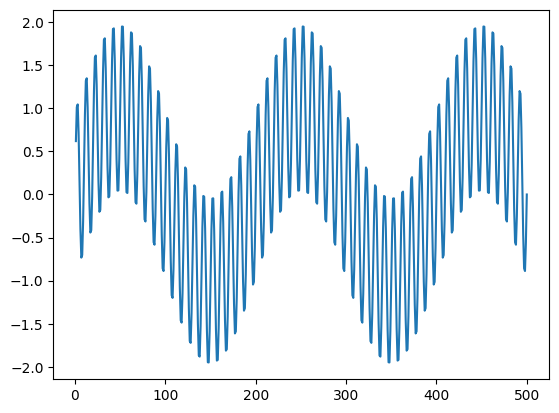

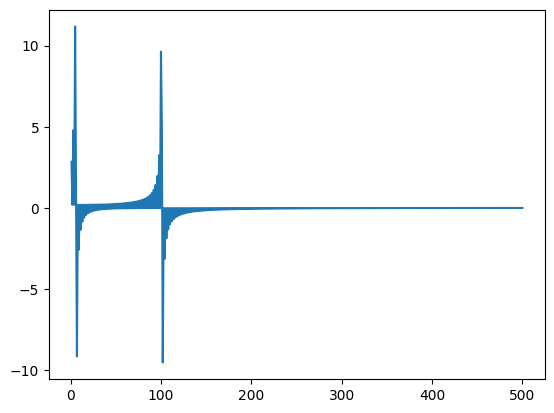

([<matplotlib.lines.Line2D at 0x793da1123d40>], None)

In [8]:
n = np.linspace(1,500,500)

#two harmonics signal
xx = np.sin(2*np.pi*n/10) + np.sin(2*np.pi*n/200)  #+ np.sin(2*np.pi*n/50)
mp.plot(n,xx), mp.show()
mp.plot(n,fftpack.dct(xx, norm='ortho')), mp.show()

**Sparse Sampling** \\
Lets assume that we only consider $n$ of this ($n \ll N$).

For this lets define a sparsifying vector sp which has only $n$ 1's and rest zeros placed in random places.

So sparsed data $xp = xx*sp$.

The trick is that these $n$ samples are randomly taken.

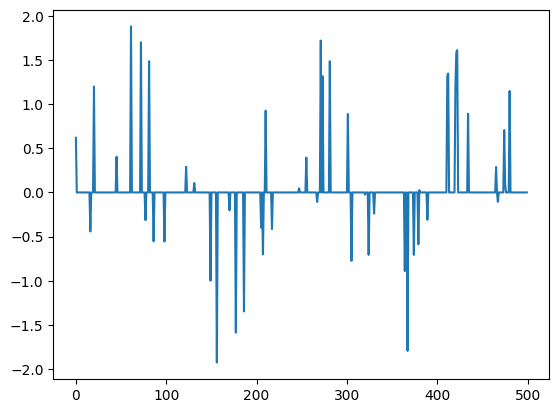

([<matplotlib.lines.Line2D at 0x793da1759520>], None)

In [9]:
N = len(xx) #length of actual N
n = 50 #number of nonzero samples in our sparse signal
sp = np.array([1] * n + [0] * (N-n)) #n 1's and (N-n) 0's
np.random.shuffle(sp)

xp = xx*sp
mp.plot(xp), mp.show()

### Using Optimization
The trick of compressive sensing is that we try to use optimization in order to know the unknown from what is known!

So let us think what we know.

1- We know $xp$  the random-subNyquist-sampled signal and $sp$.

2- We know that the signal is sparse in DCT domain.

So lets try to look into the DCT domain. Lets assume that the DCT of the signal is $XX$. So IDCT of it should give us $xp$ back.

Lets define an optimization problem to do this.

What are the DCT samples that will give rise to a time domain signal which has the values of $xp$ at $sp$ time-indices. \\
We start with an intial estimate $XX$ which we will update in each iteration. \\
The cost function will be Euclidean distance between $xp$ and IDCT of $XX$.

         Current function value: 0.000000
         Iterations: 6
         Function evaluations: 40592
         Gradient evaluations: 81


/usr/local/lib/python3.12/dist-packages/scipy/optimize/_minimize.py:779: OptimizeWarning: Desired error not necessarily achieved due to precision loss.
  res = _minimize_bfgs(fun, x0, args, jac, callback, **options)


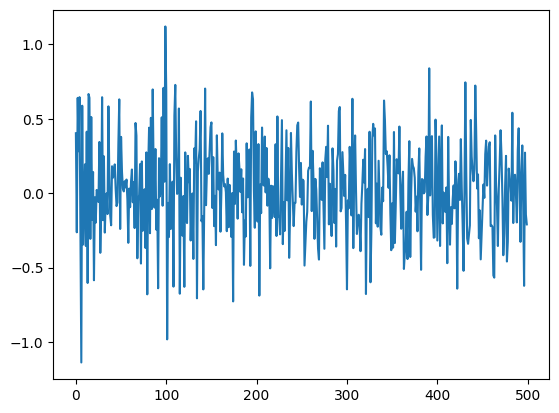

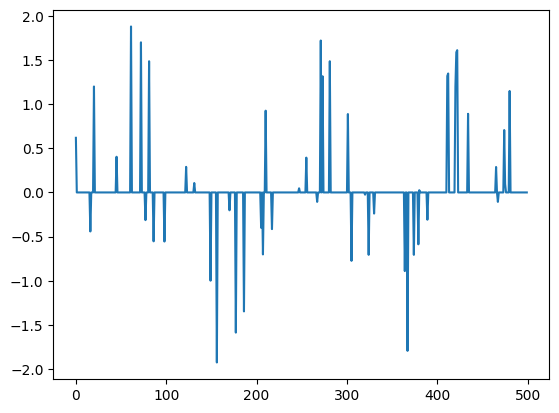

([<matplotlib.lines.Line2D at 0x793d9ef8e4b0>], None)

In [10]:

XX = np.random.rand(N)
def cost_cs(XX):   #given the measured xp and a generic X find the L1 norm
    xd = fftpack.idct(XX, norm='ortho') #derived x from X
    xdn = xd*sp
    return np.linalg.norm((xdn - xp), ord=2)

seed = np.zeros(N)

CS = optimize.minimize(cost_cs, seed, options={'disp': True})

xrecon = fftpack.idct(CS.x, norm='ortho')
mp.plot(CS.x), mp.show()
mp.plot(xrecon), mp.show()

### Redfining the Optimization
Hmmmm. Enen though the optimization has not finished doing its job if we look at the result we seem to have achieved what we asked for!

The reconstructed signal $xrecon$ looks exactly like $xp$. So we did achieve what we wanted (theoritically speaking) but we want more.

What else can we do?

Lets add a condition that we want to optimize $||xrecon - xp ||$ but we also want to keep XX sparse, i.e. the $L0$ norm of $XX$ should be less than $n$.

Iteration limit reached    (Exit mode 9)
            Current function value: 1.0203324220943625e-05
            Iterations: 100
            Function evaluations: 51248
            Gradient evaluations: 101


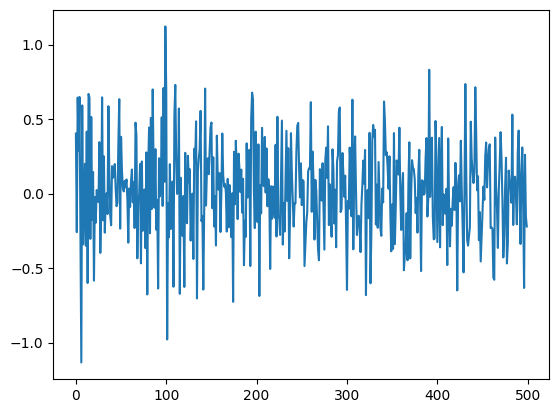

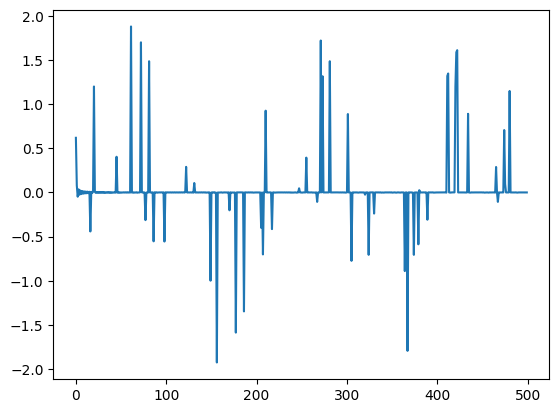

([<matplotlib.lines.Line2D at 0x793d9c69e3f0>], None)

In [11]:
XX = np.random.rand(N)
def cost_cs(XX):   #given the measured xp and a generic X find the L1 norm
    xd = fftpack.idct(XX, norm='ortho') #derived x from X
    xdn = xd*sp
    return np.linalg.norm((xdn - xp), ord=2)

cons = ({'type': 'ineq',
          'fun' : lambda XX: n - np.linalg.norm(XX,ord=0)})

#seed = np.random.rand(N)
seed = np.zeros(N)

CS = optimize.minimize(cost_cs, seed, constraints=cons, options={'disp': True})

xrecon = fftpack.idct(CS.x, norm='ortho')
mp.plot(CS.x), mp.show()
mp.plot(xrecon), mp.show()

### Re-redfining the Optimization: L1 Magic!!
Hmmmm. It seems its not working the way we want it to work. What else can we do?

It seems achieving $xrecon = xp$ is an easy task, because its sparse anyway.

So lets keep this as a condition (instead of making it the cost-function). And minimize $XX$. And let us use $L1$ norm here so as to keep the error under control. Remember that even though $L2$ norm is smooth, it has a square and blows up the error. So in wildly uknown problems like what we dealing with here, its better to use $L1$ norm.

In [12]:
XX = np.random.rand(N)
def cost_cs(XX):   #given the measured xp and a generic X find the L1 norm
    return np.linalg.norm(XX, ord=1)

cons = ({'type': 'eq',
          'fun' : lambda XX : np.linalg.norm(xp - fftpack.idct(XX, norm='ortho')*sp, ord = 2)})

seed = np.random.rand(N)
#seed = np.zeros(N)

CS = optimize.minimize(cost_cs, seed, constraints=cons, options={'disp': True})

Iteration limit reached    (Exit mode 9)
            Current function value: 50.20279944729841
            Iterations: 100
            Function evaluations: 50926
            Gradient evaluations: 101


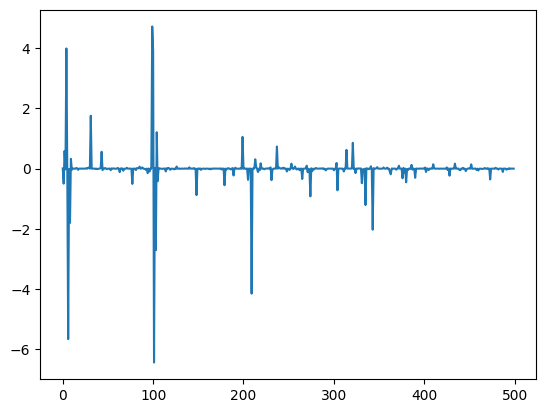

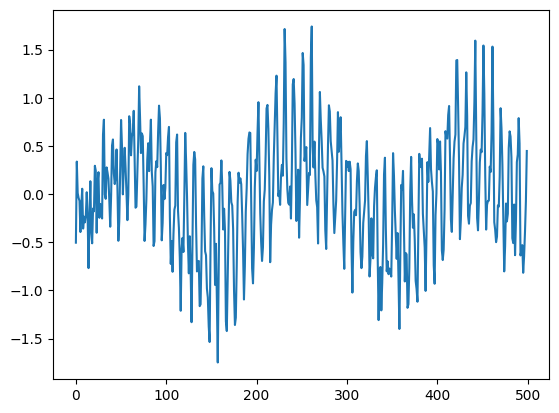

([<matplotlib.lines.Line2D at 0x7bb109453a00>], None)

In [ ]:
xrecon = fftpack.idct(CS.x, norm='ortho')
mp.plot(CS.x), mp.show()
mp.plot(xrecon), mp.show()

## Conclusions

Sentinel-1: urban samples have a wider amplitude distribution in both cities. Grass in Kraków has a lower return; forest in Olkusz overlaps more with urban pixels.
Replacing two LSBs changed **74.87%** of pixels by at most **3 DN**, with no visible degradation at the displayed scale.
The **64 DN** histograms are identical. The **1 DN** histogram reveals changes and smoother counts within groups of four levels.
Fine histogram patterns can suggest manipulation, but a histogram alone cannot reliably confirm it.